# Supervised Learning: Logistic Regression, Decision Tree & KNN

**Problem:** predict whether a student `needs_support` (Yes/No) from attendance, previous score, study hours, LMS clicks and assignment completion.

This is **classification** (the answer is a category). Regression predicts a number instead. The dataset is synthetic (500 students), so I used it for practice only.

In [1]:
# Colab already includes pandas, NumPy, matplotlib and scikit-learn.
# Therefore, no installation command is normally required.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# Make the printed tables easier to read.
pd.set_option("display.max_columns", None)
np.set_printoptions(precision=3, suppress=True)

## 1. Load and check the data
Before modelling I checked the shape, data types and missing values (none). `student_id` is only an identifier, so I never use it as a feature.

I split the data **before** fitting anything. `stratify=y` keeps the same Yes/No ratio (about 66% / 34%) in the training and test sets.

In [2]:
students = pd.read_csv('/content/sample_data/student_data_support.csv')

In [4]:
print("Rows, columns:", students.shape)
print (students.info())
display(students.head())
print("\nMissing values per column:")
display(students.isna().sum().to_frame("missing_values"))
display(students.describe())
classification_features = [
    "attendance",
    "previous_score",
    "study_hours",
    "lms_clicks",
    "assignment_completion"

]

X_cls = students[classification_features]
y_cls = students["needs_support"]

# Split before fitting any preprocessing or model.
# stratify=y_cls keeps a similar Yes/No proportion in both subsets.
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.25,
    stratify=y_cls,
    random_state=42,
)
print("Traning data:", X_train_cls.shape)
print("Test data:", X_test_cls.shape)
print("Training target proportions:")
display(y_train_cls.value_counts(normalize=True).round(3))

Rows, columns: (500, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             500 non-null    object 
 1   attendance             500 non-null    float64
 2   previous_score         500 non-null    float64
 3   study_hours            500 non-null    float64
 4   lms_clicks             500 non-null    int64  
 5   assignment_completion  500 non-null    float64
 6   needs_support          500 non-null    object 
 7   final_score            500 non-null    float64
dtypes: float64(5), int64(1), object(2)
memory usage: 31.4+ KB
None


,student_id,attendance,previous_score,study_hours,lms_clicks,assignment_completion,needs_support,final_score
0,S0001,81.7,87.1,4.9,33,75.2,No,74.6
1,S0002,65.5,80.5,3.4,31,72.0,Yes,65.0
2,S0003,87.0,57.9,4.1,74,88.5,Yes,68.3
3,S0004,89.3,47.0,6.4,52,85.8,No,63.2
4,S0005,54.6,26.5,5.0,40,60.9,Yes,45.5



Missing values per column:


,missing_values
student_id,0
attendance,0
previous_score,0
study_hours,0
lms_clicks,0
assignment_completion,0
needs_support,0
final_score,0


,attendance,previous_score,study_hours,lms_clicks,assignment_completion,final_score
count,500.000000,500.00000,500.000000,500.000000,500.000000,500.000000
mean,77.700200,67.35300,5.001200,41.744000,81.084200,64.717800
std,11.188189,14.10232,2.217113,21.591917,13.693888,8.780778
min,47.200000,25.00000,0.000000,0.000000,36.000000,39.400000
25%,69.975000,57.82500,3.500000,27.750000,71.575000,58.900000
50%,78.050000,68.15000,5.000000,42.000000,82.550000,65.000000
75%,85.025000,76.37500,6.400000,56.000000,91.900000,70.600000
max,100.000000,100.00000,11.200000,109.000000,100.000000,95.500000


Traning data: (375, 5)
Test data: (125, 5)
Training target proportions:


,proportion
needs_support,
No,0.661
Yes,0.339


## 2. Logistic Regression
Logistic regression gives a probability between 0 and 1. If P(Yes) ≥ 0.5, it predicts Yes.

I **scaled** the features first because they have very different ranges (clicks vs. percentages). I fit the scaler on the **training data only** to avoid data leakage.

For the new student, P(Yes) = 0.494, just under the threshold. The model said "No", but this is a borderline case where a teacher should still take a look.

In [5]:
#1 Import required external libraries
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


# 2. Define the features and target for classification
classification_features = ["attendance", "previous_score", "study_hours", "lms_clicks"]
X_cls = students[classification_features]
y_cls = students["needs_support"]


# 3 Split before fitting any preprocessing or model.
# stratify=y_cls keeps a similar Yes/No proportion in both subsets.
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.25,
    stratify=y_cls,
    random_state=42,
)
#4.  Scale the data before fitting into model
scaler = StandardScaler()

# Fit on training data and transform both training and test sets
X_train_scaled = scaler.fit_transform(X_train_cls)
X_test_scaled = scaler.transform(X_test_cls)


#5 Initialize and fit the Logistic Regression model
logistic_model = LogisticRegression(random_state=42)

#6 Train the model on the scaled training features
logistic_model.fit(X_train_scaled, y_train_cls)


#7 Test the performance of your model
train_accuracy = logistic_model.score(X_train_scaled, y_train_cls)
test_accuracy = logistic_model.score(X_test_scaled, y_test_cls)

print(f"Training Accuracy: {train_accuracy:.3f}")
print(f"Test Accuracy:     {test_accuracy:.3f}")


# 3. Create a DataFrame for a new student (feature names and order must match X_cls)
new_student_cls = pd.DataFrame([{
    "attendance": 69,
    "previous_score": 54,
    "study_hours": 8,
    "lms_clicks": 13,
}])

# Scale the new student data using the already fitted scaler
new_student_scaled = scaler.transform(new_student_cls)

# Predict the class label and probabilities
prediction = logistic_model.predict(new_student_scaled)[0]
prediction_proba = logistic_model.predict_proba(new_student_scaled)[0]


# Display results
print("Logistic Regression Prediction:", prediction)
print(f"Probabilities — No: {prediction_proba[0]:.3f}, Yes: {prediction_proba[1]:.3f}")

Training Accuracy: 0.827
Test Accuracy:     0.768
Logistic Regression Prediction: No
Probabilities — No: 0.506, Yes: 0.494


### Using a Pipeline
A `Pipeline` combines the scaler and the model into one object. I got exactly the same results with less code, and it's safer because the scaling is always done in the right order.

In [6]:
#1  Import required library
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# 2. Define the features and target for classification
classification_features = ["attendance", "previous_score", "study_hours", "lms_clicks"]
X_cls = students[classification_features]
y_cls = students["needs_support"]


# 3 Split before fitting any preprocessing or model.
# stratify=y_cls keeps a similar Yes/No proportion in both subsets.
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.25,
    stratify=y_cls,
    random_state=42,
)
#4. Build and train the Logistic Regression pipeline
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(random_state=42))
])

#5 Train on the training data (X_train_cls, y_train_cls)
logistic_pipeline.fit(X_train_cls, y_train_cls)

#6 Calculate accuracy directly using the pipeline
train_acc = logistic_pipeline.score(X_train_cls, y_train_cls)
test_acc = logistic_pipeline.score(X_test_cls, y_test_cls)

#7 Create a DataFrame for a new student (feature names and order must match X_cls)
new_student_cls = pd.DataFrame([{
    "attendance": 69,
    "previous_score": 54,
    "study_hours": 8,
    "lms_clicks": 13,
}])

# 8 Predict the class label and probability
prediction = logistic_pipeline.predict(new_student_cls)[0]
prediction_proba = logistic_pipeline.predict_proba(new_student_cls)[0]

# 9 Display results
print(f"Training Accuracy: {train_acc:.3f}")
print(f"Test Accuracy:     {test_acc:.3f}")
print("Logistic Regression Prediction:", prediction)
print(f"Probabilities — No: {prediction_proba[0]:.3f}, Yes: {prediction_proba[1]:.3f}")

Training Accuracy: 0.827
Test Accuracy:     0.768
Logistic Regression Prediction: No
Probabilities — No: 0.506, Yes: 0.494


## 3. Decision Tree
A decision tree learns if-then rules, e.g. "if previous_score ≤ 65.5 then …". It **doesn't need scaling**, because each split compares one feature with a threshold.

`max_depth=3` keeps the tree small and easy to read. The test accuracy was 0.768. Recall for the "Yes" class (0.67) is lower than for "No", so it misses some students who need help.

In [ ]:
# Begin with a small, interpretable tree.
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train_cls, y_train_cls)

tree_train_pred = tree_model.predict(X_train_cls)
tree_test_pred = tree_model.predict(X_test_cls)

tree_train_accuracy = accuracy_score(y_train_cls, tree_train_pred)
tree_test_accuracy = accuracy_score(y_test_cls, tree_test_pred)

print(f"Decision Tree training accuracy: {tree_train_accuracy:.3f}")
print(f"Decision Tree test accuracy:     {tree_test_accuracy:.3f}")
print("\nDetailed test-set results:")
print(classification_report(y_test_cls, tree_test_pred))

Decision Tree training accuracy: 0.856
Decision Tree test accuracy:     0.768

Detailed test-set results:
              precision    recall  f1-score   support

          No       0.83      0.82      0.82        83
         Yes       0.65      0.67      0.66        42

    accuracy                           0.77       125
   macro avg       0.74      0.74      0.74       125
weighted avg       0.77      0.77      0.77       125



## 4. Multi-class Logistic Regression
Here the target has three classes: High / Medium / Low dropout risk. The **multinomial** version gives a probability for each class, and the probabilities add up to 1.

The "Medium" class was the hardest to predict (F1 0.52), probably because it sits between the other two.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset
# Adjust path if student_data2.csv is uploaded in Colab session storage
students = pd.read_csv("/content/sample_data/student_data2.csv")

# 2. Define features (X) and target (y)
classification_features = [
    "attendance",
    "previous_score",
    "study_hours",
    "lms_clicks",
]
X_cls = students[classification_features]
y_cls = students["dropout_risk"]  # Target with classes: 'High', 'Medium', 'Low'

# 3. Split into training and testing sets (using stratify to preserve class proportions)
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.25, stratify=y_cls, random_state=42
)

# 4. Build a pipeline with StandardScaler and Multinomial Logistic Regression
logistic_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                multi_class="multinomial", solver="lbfgs", random_state=42
            ),
        ),
    ]
)

# 5. Train the model
logistic_pipeline.fit(X_train_cls, y_train_cls)

# 6. Evaluate the model performance on the test set
y_train_pred = logistic_pipeline.predict(X_train_cls)
y_test_pred = logistic_pipeline.predict(X_test_cls)

print(f"Training Accuracy: {accuracy_score(y_train_cls, y_train_pred):.3f}")
print(f"Test Accuracy: {accuracy_score(y_test_cls, y_test_pred):.3f}\n")
print("Detailed Classification Report:")
print(classification_report(y_test_cls, y_test_pred))

# 7. Predict dropout risk and class probabilities for a new student case
new_student = pd.DataFrame(
    [
        {
            "attendance": 65,
            "previous_score": 48,
            "study_hours": 3,
            "lms_clicks": 10,
        }
    ]
)

predicted_risk = logistic_pipeline.predict(new_student)[0]
predicted_probs = logistic_pipeline.predict_proba(new_student)[0]
class_names = logistic_pipeline.classes_  # Array of class labels

print("--- Prediction for New Student ---")
print("Predicted Dropout Risk:", predicted_risk)
print("Class Probabilities:")
for cls_name, prob in zip(class_names, predicted_probs):
  print(f"  {cls_name}: {prob:.3f}")

Training Accuracy: 0.743
Test Accuracy: 0.770

Detailed Classification Report:
              precision    recall  f1-score   support

        High       0.89      0.53      0.67        15
         Low       0.81      0.95      0.88        60
      Medium       0.57      0.48      0.52        25

    accuracy                           0.77       100
   macro avg       0.76      0.65      0.69       100
weighted avg       0.76      0.77      0.76       100

--- Prediction for New Student ---
Predicted Dropout Risk: High
Class Probabilities:
  High: 0.675
  Low: 0.023
  Medium: 0.303


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


## 5. A small tree I can follow by hand
On a 12-student toy dataset, the tree chose `previous_score` with threshold 65.5 as the first split. That's the split that best separates Yes from No.

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

students = pd.DataFrame({
    "attendance": [92, 85, 78, 76, 74, 70, 68, 60, 82, 88, 80, 77],
    "previous_score": [78, 72, 60, 68, 75, 65, 55, 80, 62, 90, 70, 66],
    "needs_support": ["No", "No", "Yes", "No", "Yes", "Yes",
                      "Yes", "Yes", "Yes", "No", "No", "No"]
})

X = students[["attendance", "previous_score"]]
y = students["needs_support"]

# Split dataset into Training (80%) and Testing (20%) sets
# stratify=y preserves the balance of "Yes" and "No" in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
model = DecisionTreeClassifier(max_depth=2, random_state=42)
model.fit(X_train, y_train)

feature = X.columns[model.tree_.feature[0]]
threshold = model.tree_.threshold[0]

print("Selected feature:", feature)
print("Selected threshold:", round(threshold, 2))

Selected feature: previous_score
Selected threshold: 65.5


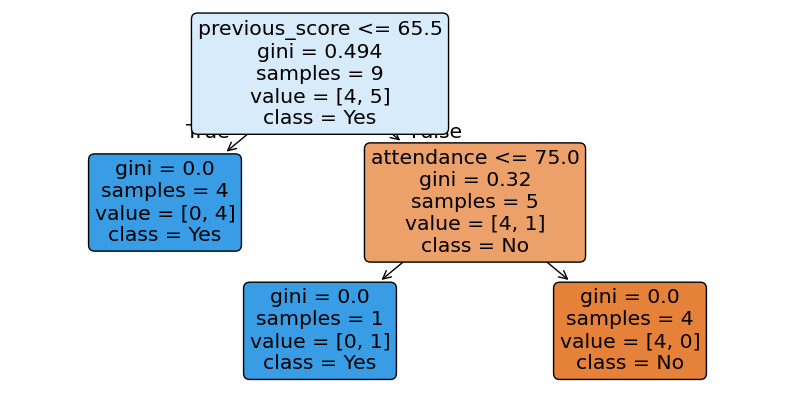

Prediction for the new student: Yes


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

students = pd.DataFrame({
    "attendance": [92, 85, 78, 76, 74, 70, 68, 60, 82, 88, 80, 77],
    "previous_score": [78, 72, 60, 68, 75, 65, 55, 80, 62, 90, 70, 66],
    "needs_support": ["No", "No", "Yes", "No", "Yes", "Yes",
                      "Yes", "Yes", "Yes", "No", "No", "No"]
})

X = students[["attendance", "previous_score"]]
y = students["needs_support"]

# Split dataset into Training (80%) and Testing (20%) sets
# stratify=y preserves the balance of "Yes" and "No" in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = DecisionTreeClassifier(max_depth=2, random_state=42)
model.fit(X_train, y_train)

plt.figure(figsize=(10, 5))
plot_tree(model, feature_names=X.columns,
          class_names=model.classes_,
          filled=True, rounded=True)
plt.show()

# Make a prediction for a new unseen student
new_student =pd.DataFrame({"attendance": [72],
                           "previous_score": [59]})
prediction = model.predict(new_student)[0]
print("Prediction for the new student:", prediction)

## 6. Comparing Logistic Regression vs Decision Tree
Both models have a train–test gap of about 0.08, so neither is badly overfitting. Their test accuracy is similar (0.75–0.77).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# ---------------------------------------------------------
# Step 1: Feature & Target Isolation + Stratified Train/Test Split
# ---------------------------------------------------------
# Features (X) and Target (y)
features = ["attendance", "previous_score", "study_hours", "lms_clicks", "assignment_completion"]
X = students[features]
y = students["needs_support"]  # Target indicating risk level

# Stratified split ensures equal class proportion in both subsets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# ---------------------------------------------------------
# Step 2: Logistic Regression (Requires Feature Scaling)
# ---------------------------------------------------------
log_reg_pipeline = Pipeline([
    ("scaler", StandardScaler()),  # Scale features to mean=0, std=1
    ("classifier", LogisticRegression(random_state=42))
])

log_reg_pipeline.fit(X_train, y_train)

log_reg_train_acc = accuracy_score(y_train, log_reg_pipeline.predict(X_train))
log_reg_test_acc  = accuracy_score(y_test, log_reg_pipeline.predict(X_test))

# ---------------------------------------------------------
# Step 3: Decision Tree (Does not require scaling)
# ---------------------------------------------------------
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)

tree_train_acc = accuracy_score(y_train, tree_model.predict(X_train))
tree_test_acc  = accuracy_score(y_test, tree_model.predict(X_test))

# ---------------------------------------------------------
# Step 4: Summary Comparison Table
# ---------------------------------------------------------
results_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree (max_depth=3)"],
    "Training Accuracy": [log_reg_train_acc, tree_train_acc],
    "Test Accuracy": [log_reg_test_acc, tree_test_acc],
    "Accuracy Gap (Train - Test)": [
        log_reg_train_acc - log_reg_test_acc,
        tree_train_acc - tree_test_acc
    ]
})

print(results_df.round(3))

                         Model  Training Accuracy  Test Accuracy  \
0          Logistic Regression              0.832          0.752   
1  Decision Tree (max_depth=3)              0.856          0.768   

   Accuracy Gap (Train - Test)  
0                        0.080  
1                        0.088  


## 7. Generalisation: how deep should the tree be?
**5-fold cross-validation** (my own summary):
1. Split the training data into 5 parts.
2. Train on 4 parts and validate on the 5th, rotating 5 times.
3. Average the 5 scores.

This gives a more reliable estimate than one split, and the test set stays untouched.

**What I saw:** as the depth grows, training accuracy goes up to 1.0, but test and CV accuracy stop improving after about depth 3. A very deep tree **memorises** the training data, which is overfitting.

,max_depth,training_accuracy,test_accuracy,mean_cv_accuracy
0,1,0.763,0.664,0.755
1,2,0.795,0.680,0.752
2,3,0.856,0.768,0.797
3,4,0.875,0.744,0.771
4,5,0.904,0.728,0.784
5,8,0.981,0.704,0.739
6,12,1.000,0.728,0.728
7,None,1.000,0.728,0.736


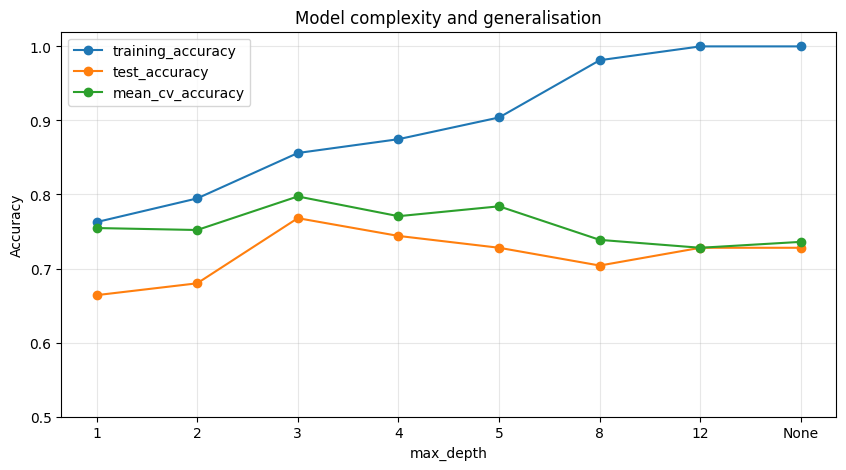

In [ ]:
from sklearn.model_selection import cross_val_score
depth_results = []

for depth in [1, 2, 3, 4, 5, 8, 12, None]:
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=42)
    candidate.fit(X_train_cls, y_train_cls)

    train_acc = candidate.score(X_train_cls, y_train_cls)
    test_acc = candidate.score(X_test_cls, y_test_cls)

    # 1. Compute 5-fold cross-validation and take the mean score
    cv_scores = cross_val_score(candidate, X_train_cls, y_train_cls, cv=5)
    cv_acc = cv_scores.mean()


    depth_results.append({
        "max_depth": "None" if depth is None else str(depth),
        "training_accuracy": train_acc,
        "test_accuracy": test_acc,
        "mean_cv_accuracy": cv_acc,
    })

depth_table = pd.DataFrame(depth_results)
display(depth_table.round(3))

depth_table.plot(
    x="max_depth",
    y=["training_accuracy", "test_accuracy", "mean_cv_accuracy"],
    marker="o",
    figsize=(10, 5),
)
plt.ylim(0.5, 1.02)
plt.ylabel("Accuracy")
plt.title("Model complexity and generalisation")
plt.grid(alpha=0.3)
plt.show()

## 8. K-Nearest Neighbours (KNN)
KNN predicts by looking at the *k* closest training students and taking a majority vote. It's distance-based, so **scaling is essential**. Without it, a feature with big numbers (like clicks) would dominate the distance.

Plotting the toy data helped me see it: the "Yes" students cluster at low attendance and low scores.

In [ ]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X = pd.DataFrame({
    "attendance": [92, 68, 81, 74, 88, 63, 95, 71, 84, 66],
    "previous_score": [78, 55, 70, 60, 82, 50, 90, 58, 75, 52],
    "lms_clicks": [40, 12, 28, 18, 38, 9, 45, 15, 32, 10]
})
y = ["No", "Yes", "No", "Yes", "No",
     "Yes", "No", "Yes", "No", "Yes"]

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)
model.fit(X, y)

new_student = pd.DataFrame({
    "attendance": [70],
    "previous_score": [57],
    "lms_clicks": [14]
})

prediction = model.predict(new_student)[0]
print("Needs support:", prediction)

Needs support: Yes


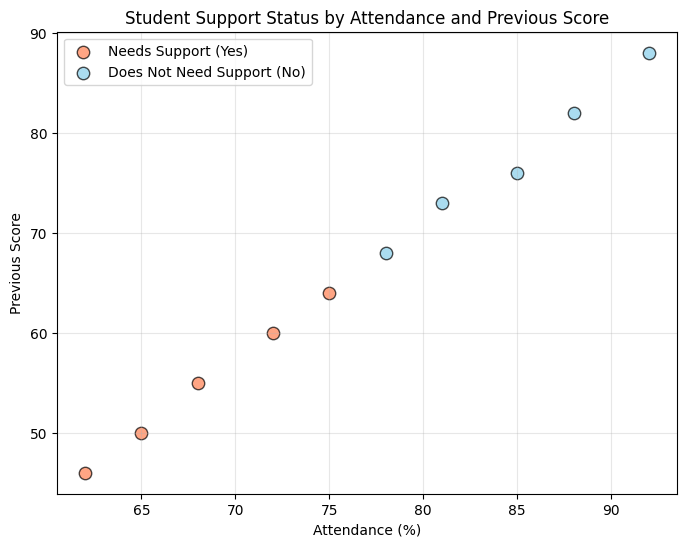

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# Re-establish the small dataset from cell [2] for plotting
students_plot = pd.DataFrame({
    "attendance": [92, 88, 85, 81, 78, 75, 72, 68, 65, 62],
    "previous_score": [88, 82, 76, 73, 68, 64, 60, 55, 50, 46],
    "needs_support": ["No", "No", "No", "No", "No", "Yes", "Yes", "Yes", "Yes", "Yes"]
})

# Create the figure
plt.figure(figsize=(8, 6))

# Separate the data by the target class ('needs_support')
support_yes = students_plot[students_plot["needs_support"] == "Yes"]
support_no = students_plot[students_plot["needs_support"] == "No"]

# Plot students who DO need support
plt.scatter(
    support_yes["attendance"],
    support_yes["previous_score"],
    color="coral",
    label="Needs Support (Yes)",
    alpha=0.7,
    s=80,
    edgecolors="k"
)

# Plot students who DO NOT need support
plt.scatter(
    support_no["attendance"],
    support_no["previous_score"],
    color="skyblue",
    label="Does Not Need Support (No)",
    alpha=0.7,
    s=80,
    edgecolors="k"
)

# Add labels, title, and legend
plt.xlabel("Attendance (%)")
plt.ylabel("Previous Score")
plt.title("Student Support Status by Attendance and Previous Score")
plt.legend()
plt.grid(alpha=0.3)

# Display the plot
plt.show()

In [ ]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X = pd.DataFrame({
    "attendance": [92, 88, 85, 81, 78, 75, 72, 68, 65, 62],
    "previous_score": [88, 82, 76, 73, 68, 64, 60, 55, 50, 46]
})
y = ["No", "No", "No", "No", "No",
     "Yes", "Yes", "Yes", "Yes", "Yes"]

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)
model.fit(X, y)

new_student = pd.DataFrame({
    "attendance": [70],
    "previous_score": [58]
})

prediction = model.predict(new_student)[0]
print("Needs support:", prediction)

Needs support: Yes


### Choosing k with GridSearchCV
I tested k = 1, 3, …, 21 with 5-fold CV on the training set only.
- A small k is sensitive to noise (overfits).
- A large k is smoother.

The best was **k = 21** (CV accuracy 0.803, test 0.760).

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
# Tune k using cross-validation on the training set.
# The pipeline prevents scaling leakage inside every validation fold.
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid={"knn__n_neighbors": list(range(1, 22, 2))},
    scoring="accuracy",
    cv=5,
)
knn_search.fit(X_train_cls, y_train_cls)

best_knn = knn_search.best_estimator_
knn_train_accuracy = best_knn.score(X_train_cls, y_train_cls)
knn_test_accuracy = best_knn.score(X_test_cls, y_test_cls)

print("Best k:", knn_search.best_params_["knn__n_neighbors"])
print(f"Best mean validation accuracy: {knn_search.best_score_:.3f}")
print(f"KNN training accuracy:         {knn_train_accuracy:.3f}")
print(f"KNN test accuracy:             {knn_test_accuracy:.3f}")

Best k: 21
Best mean validation accuracy: 0.803
KNN training accuracy:         0.827
KNN test accuracy:             0.760


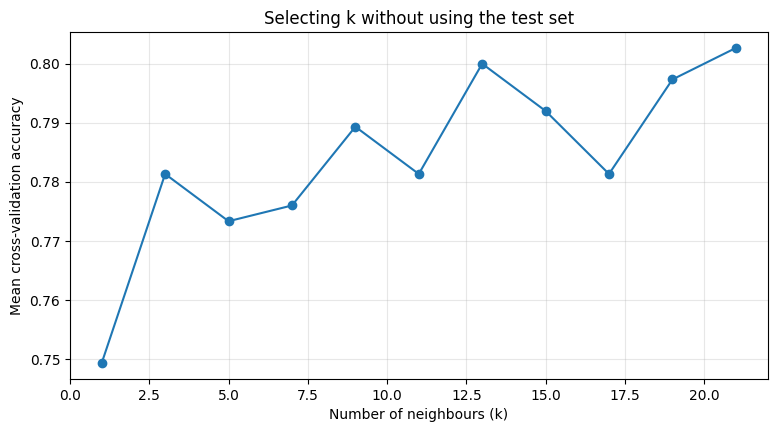

In [ ]:
# Visualize how the choice of k affects validation accuracy.
knn_cv_results = pd.DataFrame(knn_search.cv_results_)

plt.figure(figsize=(9, 4.5))
plt.plot(
    knn_cv_results["param_knn__n_neighbors"].astype(int),
    knn_cv_results["mean_test_score"],
    marker="o",
)
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Mean cross-validation accuracy")
plt.title("Selecting k without using the test set")
plt.grid(alpha=0.3)
plt.show()

## What I learned
- **Logistic regression:** gives probabilities and needs scaled features.
- **Decision tree:** easy to explain and needs no scaling, but deep trees overfit.
- **KNN:** simple, but needs scaling and a well-chosen k.
- I should choose model settings with cross-validation and keep the test set for the final check.
- These predictions should support a teacher's judgement, not replace it.